# Important Discrete Distributions {#sec-important-discrete-distributions}

Open in Google Colab (class): [![Open in Colab (class)](https://colab.research.google.com/assets/colab-badge.svg)]({{< var colabPrefix >}}class/{{< env QUARTO_DOCUMENT_FILE >}}))
Open in Google Colab (full): [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)]({{< var colabPrefix >}}{{< env QUARTO_DOCUMENT_FILE >}})

In @sec-discrete-random-variables we introduced discrete random variables, their probability mass functions (PMF), expected values, variances, and cumulative distribution functions (CDF). In this chapter we study a few distributions that appear again and again in applications: the Bernoulli, the binomial, the geometric, and the Poisson distribution.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## The Bernoulli Distribution

The distribution of the first game that we have examined is called the *Bernoulli distribution* as it is able to model situations with two possible outcomes (like success/failure, win/lose, head/tail, healthy/sick, survival/death, etc.). It is a one-parameter distribution where the parameter $p$ denotes the probability of success (e.g. winning 1 EUR, getting heads, being healthy, surviving, etc.). The PMF of a Bernoulli distributed random variable $X$ is of the same form as the PMF of our coin tossing game, only the probability of winning 1 EUR is $p$ instead of $3/4$.

:::{#def-bernoulli .ex-class}
## Bernoulli Distribution

A discrete random variable $X$ is said to follow a Bernoulli distribution with parameter $p$ (denoted by $X \sim Bernoulli(p)$) if its PMF is given by

$$
f(x) = \begin{cases}
p & \text{if } x = 1 \\
1 - p & \text{if } x = 0 \\
0 & \text{otherwise}
\end{cases}
$$

:::

Exercise: Derive the expected value and the variance of a Bernoulli distributed random variable.


:::{#exr-pmf-binomial-1 .ex-class}

## The Binomial Distribution

Consider an experiment where you toss a fair coin $3$ times independently. Write down the sample space $\Omega$ as a set of sequences (e.g., $HHH$ for three heads). Let $X$ be the random variable that counts the number of heads in the sequence. Write down the PMF of $X$, i.e. the probabilities for $X=0, X=1, X=2$.

:::

:::{.callout-important}
## Notation

Note that when we write $P(X=0)$ for example, we are condensing the notation a little bit. 
$\{X=0\}$ is an event, a subset of $\Omega$. It is a compact way to express

$$
\{\omega \in \Omega : X(\omega) = 0\}
$$

In words this means: "the set of all outcomes (sequences of coin tosses) in the sample space $\Omega$ such that the random variable $X$ takes on the value 0 (number of heads in our case)". This is another way to describe a set. Instead of explicitly listing the members of a set (as we did until now), we can also state a condition that describes them. This is especially useful when the set is large or infinite.
:::

:::{.callout-note collapse="true"}
## Solution (click to expand)

The sample space is

$$
\Omega = \left\{\begin{array}{cccc}
    HHH & HHT & HTH & HTT \\
    THH & THT & TTH & TTT \\
\end{array}\right\}
$$

and has $2^3 = 8$ equally likely of elements. It is important to note that in this sample space the elements are **sequences** (i.e. the order matters). This is relevant because we want to construct the PMF of $X$ that counts the number of heads in the sequence and we can obtain one and the same number of head from _different_ sequences (i.e. the order does not matter for $X$). Let's start counting the number of sequences that yield 0, 1, 2, and 3 heads.

- Only one sequence yields 0 heads: $TTT$. Therefore, $P(X = 0) = 1/8$.
- Three sequences yield 1 head: $HTT, THT, TTH$. Therefore, $P(X = 1) = 3/8$. This is the **sum** of the probabilities of the three sequences (it is a sum because they cannot occur simultaneously, i.e. they are mutually exclusive (disjoint) events).
- Three sequences yield 2 heads: $HHT, HTH, THH$. Therefore, $P(X = 2) = 3/8$.
- Only one sequence contains 3 heads: $HHH$. Therefore, $P(X = 3) = 1/8$.

We can write this down cleanly as

$$
f(x) = \begin{cases}
\frac{1}{8} & \text{if } x = 0 \\
\frac{3}{8} = \frac{1}{8} + \frac{1}{8} + \frac{1}{8} & \text{if } x = 1 \\
\frac{3}{8} = \frac{1}{8} + \frac{1}{8} + \frac{1}{8} & \text{if } x = 2 \\
\frac{1}{8} & \text{if } x = 3 \\
0 & \text{otherwise}
\end{cases}
$$

Now let's generalize the counting. For example, look at the sequences with one head first. Each sequence has three slots and one must be occupied by a head. Having one H means that we only have to choose in which of the slots to place the one head. Obviously, there are only three options: it is either in the first, the second or the third.

$$
\underbrace{H}_{\text{1st}}\underbrace{T}_{\text{2nd}}\underbrace{T}_{\text{3rd}}, \quad
\underbrace{T}_{\text{1st}}\underbrace{H}_{\text{2nd}}\underbrace{T}_{\text{3rd}}, \quad
\underbrace{T}_{\text{1st}}\underbrace{T}_{\text{2nd}}\underbrace{H}_{\text{3rd}}
$$

However, the situation here is exactly the same as choosing one person out for three to take a photo (@sec-counting-combinations). We can choose one slot out of three in

$$
\binom{3}{1}
$$

ways. How look at the sequences with two heads. Each sequence has three slots and two must be occupied by heads.

$$
\underbrace{H}_{\text{1st}}\underbrace{H}_{\text{2nd}}\underbrace{T}_{\text{3rd}}, \quad
\underbrace{T}_{\text{1st}}\underbrace{H}_{\text{2nd}}\underbrace{H}_{\text{3rd}}, \quad
\underbrace{H}_{\text{1st}}\underbrace{T}_{\text{2nd}}\underbrace{H}_{\text{3rd}}
$$

This is the same of choosing two persons out of 3 to take a photo. He don't care about the order of the persons in the photo just as we don't care about the order of the heads in the sequence. We can choose two slots out of three in

$$
\binom{3}{2}
$$

ways. Finally, the sequences with three heads is just one sequence: $HHH$. This is the same as choosing all three persons out of three to take a photo. We can choose three slots out of three in.
:::

## Binomial Distribution

The previous example showed the distribution of the number of heads in three independent tosses of a fair coin. Let's think about "head" as an outcome of an experiment with two possible outcomes like passing/failing an exam, winning/losing a game, being healthy/sick, married/unmarried, etc. Let's take one of the two possible outcomes and let's call it a "success". Think about a series of $n$ exams that you need to take and assume that in each of these the probability of success is $p$, a number between 0 and 1 (and also assume that the trials are independent).

A question that may concern you could be for example: how likely is it to pass all exams? Or how likely is it to pass more than 3 exams? Less than 4 exams? How many exams do you expect to pass?

These are all questions that we can answer with the help of the **binomial distribution**.
To keep it simple, let's continue the coin toss example, we will only substitute S for H and F for T and now the probability of success is $p$, a parameter, not necessarily $1/2$.

We already laid the groundwork for $n=3$ (we'll keep it for now). The sample space is the same as before but now the sequences are not necessarily equally likely.

Let $X$ be the number of exams passed. The one sequence where you don't pass any exam is $FFF$ and its probability (under independence) is $(1 - p)^3$. The sequences with one success are $SFF, FSF, FFS$ and each of them has probability $p(1-p)^2$ (one passed, two failed). The rest of the probabilities are given in the following table.

| Exams passed ($k$) | Sequences | # sequences | Sequence prob. | $P(X=k)$ |
|---|---|---|---|---|
| 0 | $FFF$ | $\binom{3}{0} = 1$ | $(1-p)^3$ | $\binom{3}{0}(1-p)^3$ |
| 1 | $SFF, FSF, FFS$ | $\binom{3}{1} = 3$ | $p(1-p)^2$ | $\binom{3}{1}p(1-p)^2$ |
| 2 | $SSF, SFS, FSS$ | $\binom{3}{2} = 3$ | $p^2(1-p)$ | $\binom{3}{2}p^2(1-p)$ |
| 3 | $SSS$ | $\binom{3}{3} = 1$ | $p^3$ | $\binom{3}{3}p^3$ |



:::{#exr-pmf-binomial}
## The Binomial Distribution

In this exercise we will again consider a coin tossing experiment where you toss a coin $n$ times independently, but this time the coin will not be fair. Instead the probability of getting a head is $p$ and the probability of getting a tail is $1 - p$. Write down the PMF of the random variable $X$ that counts the number of heads in each sequence.

:::

Text(0, 0.5, 'Probability')

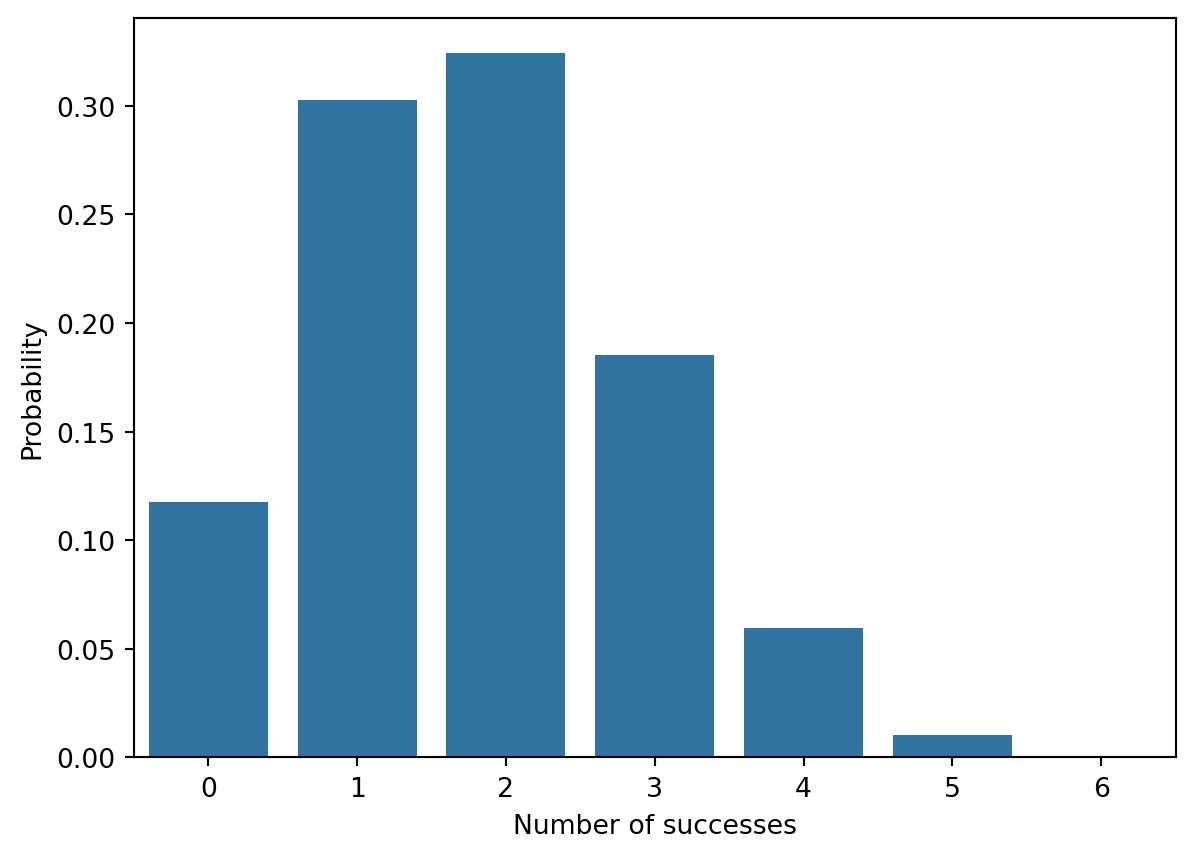

In [2]:
#| label: fig-binomial-pmf-plot
#| fig-cap: Plot of the probability mass function of the binomial distribution with parameters n=6 and p=0.3.

#ex-class
import numpy as np
from scipy.stats import binom

x = np.arange(0, 7)
y = binom.pmf(x, n=6, p=0.3)

sns.barplot(x=x, y=y)
plt.xlabel('Number of successes')
plt.ylabel('Probability')


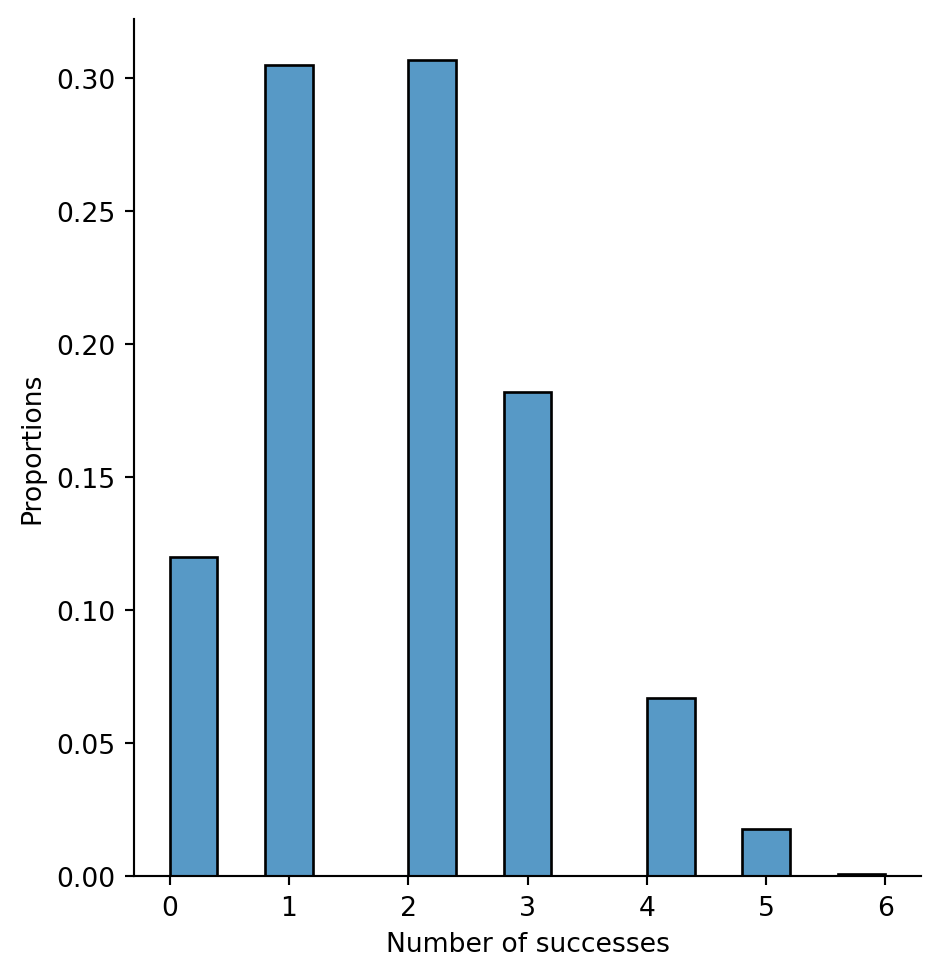

In [3]:
#| label: fig-binomial-epmf-simulated
#| caption: Empirical probability mass function of the binomial distribution with parameters n=6 and p=0.3.
#ex-class

# Simulate the binomial distribution with n=6 and p=0.3

binomial = np.random.binomial(n=6, p=0.3, size=1000)

sns.displot(x=binomial, stat='probability')
plt.xlabel('Number of successes')
plt.ylabel('Proportions')
plt.show()



:::{#exr-discrete-birthday-problem .ex-class}

You go to a party with 30 other people. Assume that birthdays are uniformly distributed over 365 days and independent between people. What is the probability that

- exactly one other person has the same birthday as you?
- no other person has the same birthday as you?
- at least one other person has the same birthday as you?
- between 2 and 4 other persons share your birthday?

:::


### Exercise (Binomial)

You offer the following game to the public. A participant tosses a fair coin four times (independently) and you pay 1 EUR
for every toss that results in a head. 

- What price would you set for the ticket?
- What price would you set if the coin is loaded and turns head only 20 percent of the time?

$$
\Omega = \left\{\begin{array}{llll}
HHHH & HHHT & HHTH & HHTT \\
HTHH & HTHT & HTTH & HTTT \\
THHH & THHT & THTH & THTT \\
TTHH & TTHT & TTTH & TTTT
\end{array}\right\}
$$

## Waiting Times

The statistical modeling of waiting times (e.g. number of hours or weeks until some event occurs) forms an important part of the applied work in statistics. Consider some examples:

- The number of days until a customer makes a purchase.
- The number of weeks until a machine breaks down.
- The number of hours until a light bulb burns out.

Assuming that these events may occur in every period with a fixed probability and assuming independence between the periods, all of these examples  

:::{#exr-geometric-distribution}
## Coin Tossing until the First Head

You toss a biased coin with probability of getting a head $p$. Assume that the tosses are independent. The random variable $X$ counts the number of tosses until the first head. Write down the PMF and CDF of $X$. Compute the following probabilities:

- The probability of getting a head on the first toss.
- The probability of waiting at least 3 tosses until the first head (for $p = 0.2$).
- The probability of waiting between 2 and 4 tosses until the first head (for $p = 0.2$).

:::

:::{.callout-note collapse="true"}
## Hint: Geometric Series (click to expand)

In the derivation of the CDF you will need an expression for the partial sum of a geometric series. The sum of the first $n$ terms of a geometric series is:

$$
\sum_{k = 0}^{n} r^k = \frac{1 - r^{n + 1}}{1 - r}, \quad r \neq 1
$$

where $r$ is the common ratio of the series. In this case, the common ratio is $1 - p$.

It is easy to show why the above equation holds:

$$
\begin{align*}
S_n &= 1 + r + r^2 + \ldots + r^{n - 1} + r^{n} \\
rS_n &= r + r^2 + \ldots + r^{n} + r^{n + 1} \\
\end{align*}
$$

Subtracting the second equation from the first gives

$$
S_n - rS_n = 1 - r^{n + 1} \Rightarrow S_n = \frac{1 - r^{n + 1}}{1 - r}
$$

:::

In [4]:
# Check it with numpy

pwr = np.array([0, 1, 2, 3, 4, 5])
series = 0.5 ** pwr
series

array([1.     , 0.5    , 0.25   , 0.125  , 0.0625 , 0.03125])

In [5]:
# Look at the partial sums

np.cumsum(series)

array([1.     , 1.5    , 1.75   , 1.875  , 1.9375 , 1.96875])

In [6]:
# Compare these to the result obtained using the formula

(1 - 0.5 ** (pwr + 1)) / (1 - 0.5)

array([1.     , 1.5    , 1.75   , 1.875  , 1.9375 , 1.96875])

:::{#exr-bulb-burnout}
## Light Bulb Burnout

A firm produces light bulbs that burn out after a random number of months. The firm offers a warranty for their products, so it is interested in the distribution of the number of months until a bulb burns out, because this will determine the number of replacements it has to provide. The analytics department of the firm has estimated that each bulb is likely to burn out with a probability of 0.02 in each month and that the burnout of each bulb is independent of the other bulbs and between months.

What is the probability that a bulb burns out after the third month?
:::

:::{#exr-rare-events}
## The Number of Rare Events

Show that the following function is a valid PMF for a discrete random variable $X$ with values in the set $\{0, 1, 2, \ldots\}$ and parameter $\lambda > 0$:

$$
f(k) = \frac{e^{-\lambda} \lambda^k}{k!}, \quad k = 0, 1, 2, \ldots
$$

Use $\lambda = 2$ and compute the probabilities of $X$ taking the values 0 and 2.

:::

:::{.callout-note collapse="true"}
## Hint (click to expand)

Use the fact that 

$$
e^{\lambda} = \frac{\lambda^{0}}{0!} + \frac{\lambda^{1}}{1!} + \frac{\lambda^{2}}{2!} + \frac{\lambda^{3}}{3!} + \ldots
$$

:::

## The Poisson Distribution as a Limit of the Binomial

The PMF in @exr-rare-events defines the **Poisson distribution** with parameter $\lambda$. It is not an arbitrary formula: it arises from the binomial distribution when the number of trials $n$ is large and the probability of success $p$ in each trial is small. Typical examples are the number of customers (out of many) who call a call center in a given minute, the number of defective items in a large batch, or the number of insurance claims in a large portfolio.

**Setup.** Fix a number $\lambda > 0$. For each $n > \lambda$ let $X_n$ follow a binomial distribution with $n$ trials and probability of success

$$
p_n = \frac{\lambda}{n},
$$

so that the expected number of successes $E(X_n) = n p_n = \lambda$ stays the same while $n$ grows. More and more trials, each one less and less likely to succeed.

:::{#thm-poisson-limit .ex-class}
## Poisson Limit of the Binomial Distribution

Under the setup above, for every fixed $k = 0, 1, 2, \ldots$

$$
\lim_{n \to \infty} \binom{n}{k} p_n^k (1 - p_n)^{n - k} = \frac{e^{-\lambda} \lambda^k}{k!}.
$$

:::

:::{.callout-important}
## The Number $e$ and Continuous Compounding

The proof needs one limit:

$$
\lim_{n \to \infty} \left(1 + \frac{x}{n}\right)^n = e^{x} \quad \text{for every real number } x.
$$

It is easiest to understand through interest on a bank deposit.

**Compounding.** You deposit 1 EUR at an annual interest rate of 100% ($x = 1$). If the bank pays interest once at the end of the year, you have $1 + 1 = 2$ EUR. If it pays half the rate, $\frac{1}{2}$, every six months, the interest from the first half-year also earns interest in the second half, and you end the year with $\left(1 + \frac{1}{2}\right)^2 = 2.25$ EUR. In general, with $n$ payments per year of $\frac{1}{n}$ each, you end with

$$
\left(1 + \frac{1}{n}\right)^n \text{ EUR}.
$$

| Compounding | $n$ | $\left(1 + \frac{1}{n}\right)^n$ |
|---|---|---|
| yearly | 1 | 2.00000 |
| half-yearly | 2 | 2.25000 |
| quarterly | 4 | 2.44141 |
| monthly | 12 | 2.61304 |
| daily | 365 | 2.71457 |
| hourly | 8760 | 2.71813 |

More frequent compounding always helps, but the gains get smaller and smaller: the amount does not grow without bound. It approaches a limit, $e = 2.71828\ldots$, the amount you would have under **continuous compounding** (interest paid at every instant). This limit is one way to *define* the number $e$.

**Other interest rates.** With an annual rate $x$ and $n$ payments of $\frac{x}{n}$ each, the end-of-year amount is $\left(1 + \frac{x}{n}\right)^n$, and under continuous compounding it approaches $e^{x}$.

**Negative rates: continuous decay.** The same holds for $x < 0$, which is the case we need with $x = -\lambda$. Think of a deposit that *loses* the fraction $\frac{\lambda}{n}$ of its value in each of $n$ periods. What is left after all $n$ periods is $\left(1 - \frac{\lambda}{n}\right)^n$, which approaches $e^{-\lambda}$ as the periods get shorter. For $\lambda = 1$: $0.35200$ with monthly losses, $0.36737$ with daily losses, and $e^{-1} = 0.36788\ldots$ in the limit.

**Connection to the binomial.** In the setup above, each of the $n$ trials fails with probability $1 - \frac{\lambda}{n}$. The probability that *all* $n$ trials fail is

$$
P(X_n = 0) = \left(1 - \frac{\lambda}{n}\right)^n,
$$

exactly the "continuously decaying" quantity, and so $P(X_n = 0) \to e^{-\lambda}$. The factor $e^{-\lambda}$ in the Poisson PMF comes from this limit.

:::

:::{.callout-note collapse="true"}
## Proof (click to expand)

**Write out the binomial coefficient.** For a fixed $k$ we have

$$
\binom{n}{k} = \frac{n!}{k!(n-k)!} = \frac{n (n - 1) \cdots (n - k + 1)}{k!},
$$

a product of $k$ factors in the numerator. Substituting $p_n = \lambda / n$ into the binomial PMF gives

$$
P(X_n = k) = \frac{n (n - 1) \cdots (n - k + 1)}{k!} \cdot \frac{\lambda^k}{n^k} \cdot \left(1 - \frac{\lambda}{n}\right)^{n - k}.
$$

**Rearrange.** Distribute the $n^k$ in the denominator over the $k$ factors of the numerator and split the last power into two parts:

$$
P(X_n = k) = \frac{\lambda^k}{k!}
\cdot \underbrace{\frac{n}{n} \cdot \frac{n - 1}{n} \cdots \frac{n - k + 1}{n}}_{A_n}
\cdot \underbrace{\left(1 - \frac{\lambda}{n}\right)^{n}}_{B_n}
\cdot \underbrace{\left(1 - \frac{\lambda}{n}\right)^{-k}}_{C_n}.
$$

The factor $\lambda^k / k!$ does not depend on $n$. We take the limit of the other three factors one at a time.

**The factor $A_n$.** Each of its factors has the form $\frac{n - j}{n} = 1 - \frac{j}{n}$ with $j \in \{0, 1, \ldots, k - 1\}$, and each converges to $1$ as $n \to \infty$. Because $k$ is fixed, $A_n$ is a product of a *fixed* number of factors, so $A_n \to 1$.

**The factor $B_n$.** This is the calculus fact above with $x = -\lambda$:

$$
B_n = \left(1 + \frac{-\lambda}{n}\right)^{n} \to e^{-\lambda}.
$$

**The factor $C_n$.** The base $1 - \lambda / n$ converges to $1$ and the exponent $-k$ is fixed, so $C_n \to 1^{-k} = 1$.

**Combine.** The limit of a product of finitely many convergent factors is the product of the limits:

$$
\lim_{n \to \infty} P(X_n = k) = \frac{\lambda^k}{k!} \cdot 1 \cdot e^{-\lambda} \cdot 1 = \frac{e^{-\lambda} \lambda^k}{k!}.
$$

:::

The theorem explains the name "distribution of rare events": the Poisson distribution counts how many of a very large number of independent, individually unlikely events actually occur, and it depends only on their expected number $\lambda = np$.

:::{.callout-important}
## Approximation Note: When to Use the Poisson Approximation

The theorem is a statement about a limit. In practice we use it as an **approximation** for a binomial distribution with a *finite* $n$:

$$
\binom{n}{k} p^k (1 - p)^{n - k} \approx \frac{e^{-\lambda} \lambda^k}{k!}, \quad \lambda = n p.
$$

Conditions for the approximation to be good:

- The trials are independent and have the same probability of success $p$ (the binomial assumptions).
- $n$ is large and $p$ is small. A common rule of thumb is $n \geq 20$ and $p \leq 0.05$; the approximation is very good for $n \geq 100$ and $n p \leq 10$.

A precise bound (Le Cam's inequality, stated here without proof): for any set of values $A$,

$$
\left| P(X \in A) - P(Y \in A) \right| \leq n p^2 = \lambda p,
$$

where $X$ is binomial with parameters $n$ and $p$ and $Y$ is Poisson with parameter $\lambda = n p$. For a fixed $\lambda$ the error is therefore small whenever $p$ is small.

:::

The following plot compares the binomial PMF with $p = \lambda / n$ to the Poisson PMF with $\lambda = 2$ for increasing values of $n$.

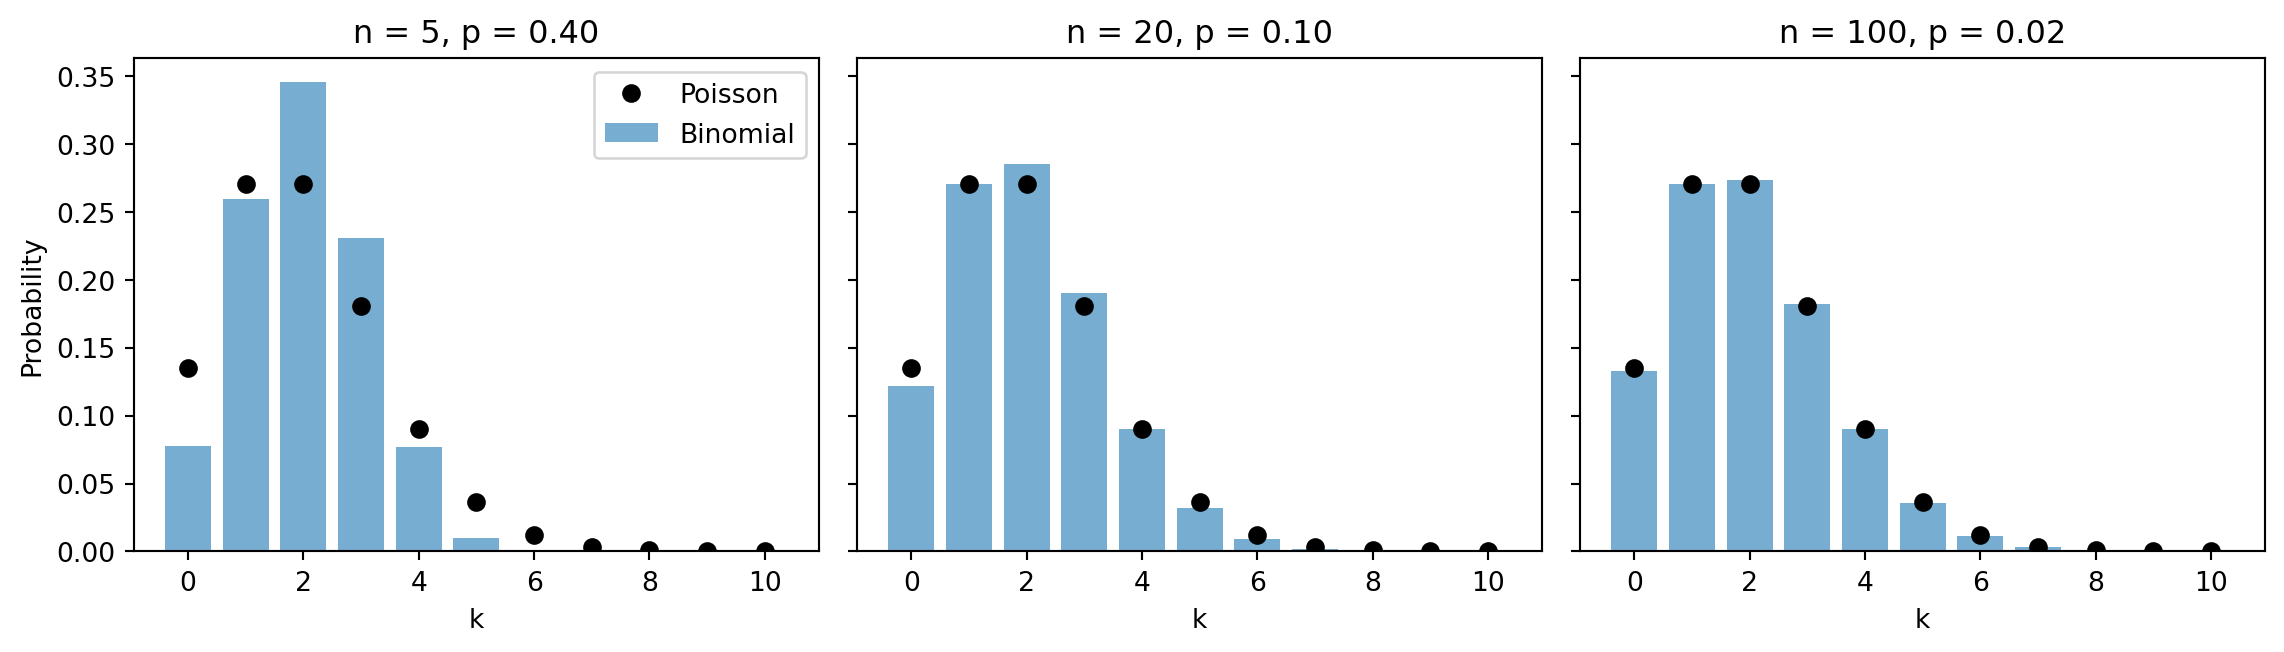

In [7]:
#| label: fig-binomial-poisson-limit
#| fig-cap: Binomial PMF with p = 2/n (bars) and Poisson PMF with lambda = 2 (dots) for increasing n.

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom, poisson

lambda_rate = 2
k_values = np.arange(0, 11)
n_values = [5, 20, 100]

fig, axes = plt.subplots(1, len(n_values), figsize=(12, 3.5), sharey=True)

for ax, n_trials in zip(axes, n_values):
    p_success = lambda_rate / n_trials
    binomial_pmf = binom.pmf(k_values, n_trials, p_success)
    poisson_pmf = poisson.pmf(k_values, lambda_rate)

    ax.bar(k_values, binomial_pmf, alpha=0.6, label="Binomial")
    ax.plot(k_values, poisson_pmf, "o", color="black", label="Poisson")
    ax.set_title(f"n = {n_trials}, p = {p_success:.2f}")
    ax.set_xlabel("k")

axes[0].set_ylabel("Probability")
axes[0].legend()
plt.tight_layout()
plt.show()

The largest difference between the two PMFs shrinks as $n$ grows, and it stays below Le Cam's bound $\lambda p = \lambda^2 / n$.

In [8]:
# Largest absolute difference between the binomial and the Poisson PMF

k_all = np.arange(0, 1001)
for n_trials in [5, 20, 100, 1000]:
    p_success = lambda_rate / n_trials
    max_difference = np.max(np.abs(binom.pmf(k_all, n_trials, p_success) - poisson.pmf(k_all, lambda_rate)))
    print(f"n = {n_trials:5d}: max difference = {max_difference:.5f}, bound lambda * p = {lambda_rate * p_success:.5f}")

n =     5: max difference = 0.07493, bound lambda * p = 0.80000
n =    20: max difference = 0.01451, bound lambda * p = 0.20000
n =   100: max difference = 0.00274, bound lambda * p = 0.04000
n =  1000: max difference = 0.00027, bound lambda * p = 0.00400


## Exercise

A company has 50 employees working in its call center serving a total of 1000 customers. At any given time
   a customer has a 0.01 probability of calling the call center and the customers act independently.

   - What is the PMF of the number of busy employees at a given time?
   - What is the probability that there are more customers calling than employees available to serve them?
   - What is the expected number of busy employees at a given time?

Furthermore, use the following approximation to calculate the probabilities:

$$
P(X = k) = \frac{\lambda^k}{k!} e^{-\lambda}
$$

where $\lambda = n \cdot p$


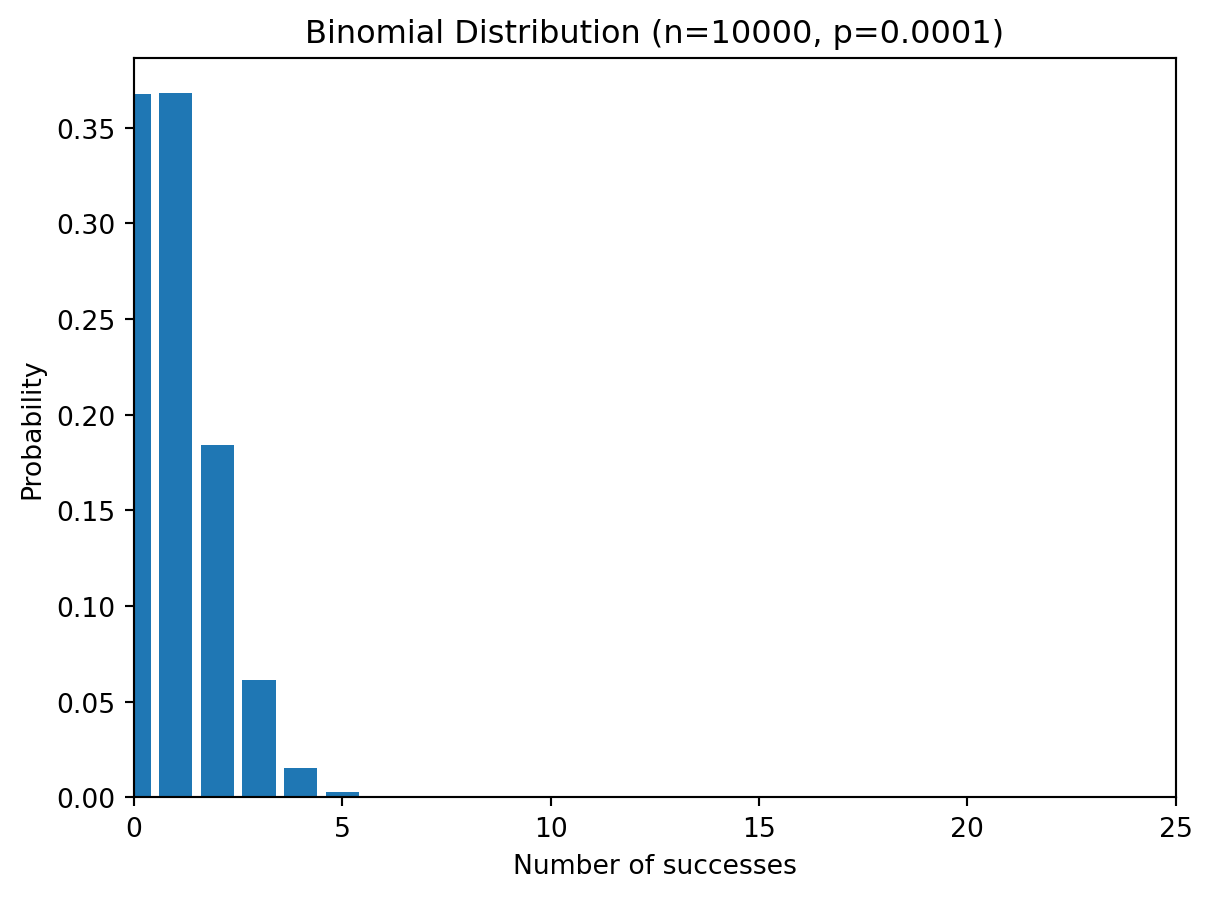

In [9]:
# Plot the binomial distribution for n=10 and p=0.5

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

n = 10000
p = 0.0001

x = np.arange(0, n+1)
pmf = binom.pmf(x, n, p)
plt.bar(x, pmf)
plt.xlabel('Number of successes')
plt.ylabel('Probability')
plt.title(f'Binomial Distribution (n={n}, p={p})')
plt.xlim(0, 25)  # Limit x-axis for better visualization
plt.show()

In [10]:
# Compute the PMF and the CDF of a binomial distribution
from scipy.stats import binom

prob_all_employed = 1 - binom.cdf(2, n, p)

print("CDF:", prob_all_employed)

CDF: 0.08029219924224273


1.0


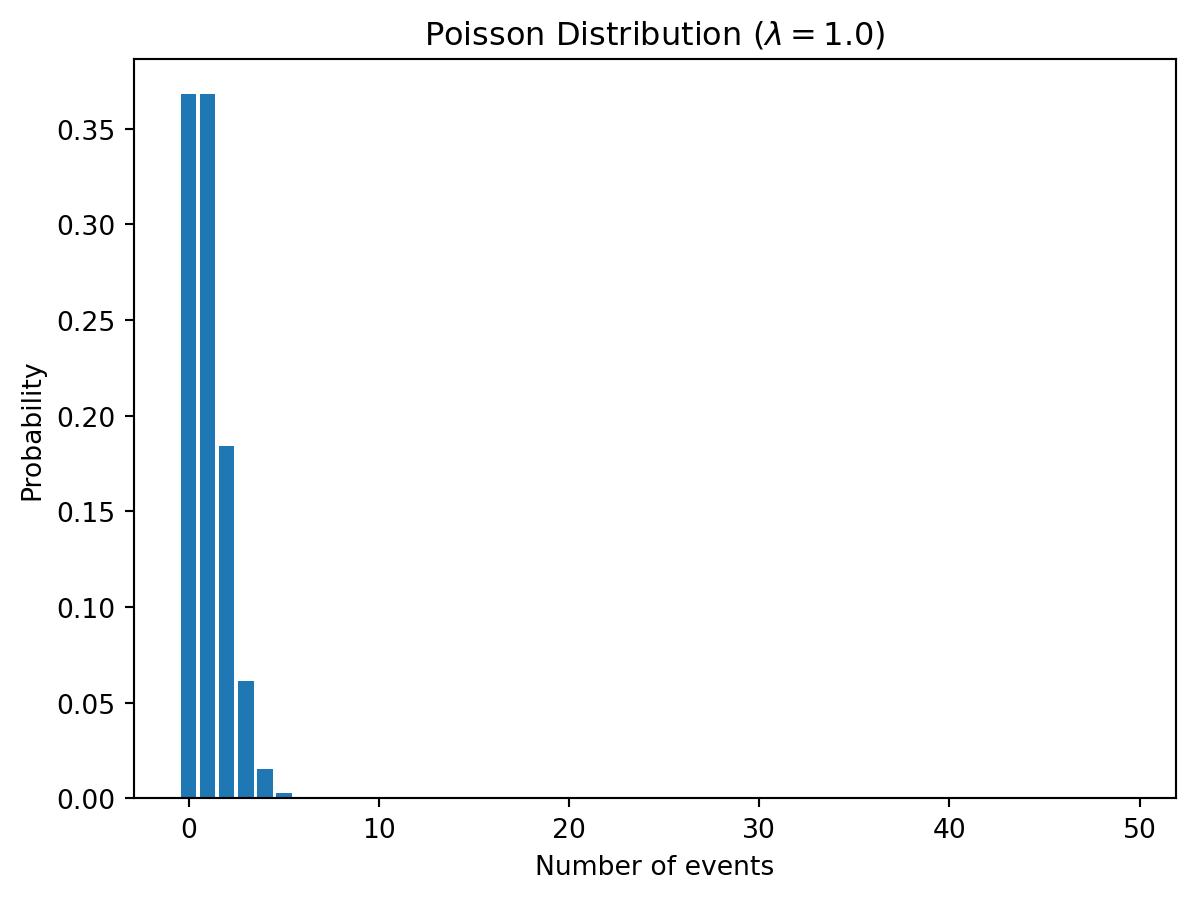

In [11]:
# Plot the Poisson distribution with lambda=n * p

from scipy.stats import poisson

lambda_ = n * p
print(lambda_)

x = np.arange(0, 50)
pmf = poisson.pmf(x, lambda_)
plt.bar(x, pmf)
plt.xlabel('Number of events')
plt.ylabel('Probability')
plt.title(rf'Poisson Distribution $(\lambda={n*p})$')
plt.show()

In [12]:
# Compute the poisson PMF and CDF

from scipy.stats import poisson

cdf_poisson = 1 - poisson.cdf(2, lambda_)

print("CDF:", cdf_poisson.round(2))

CDF: 0.08
